# L8 · RAG: responder con las políticas de ACME y citar la fuente

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L6](L06-Embeddings.ipynb) y [L7](L07-VectorStores.ipynb) aprendimos a **encontrar** los fragmentos de las políticas de ACME que se parecen a una pregunta. Claude no conoce esos documentos. Hoy le damos los fragmentos recuperados y le pedimos que conteste **solo con ellos y citando de dónde sale cada dato**. Eso es **RAG** (*Retrieval-Augmented Generation*): recuperar primero, generar después.

## Qué construimos

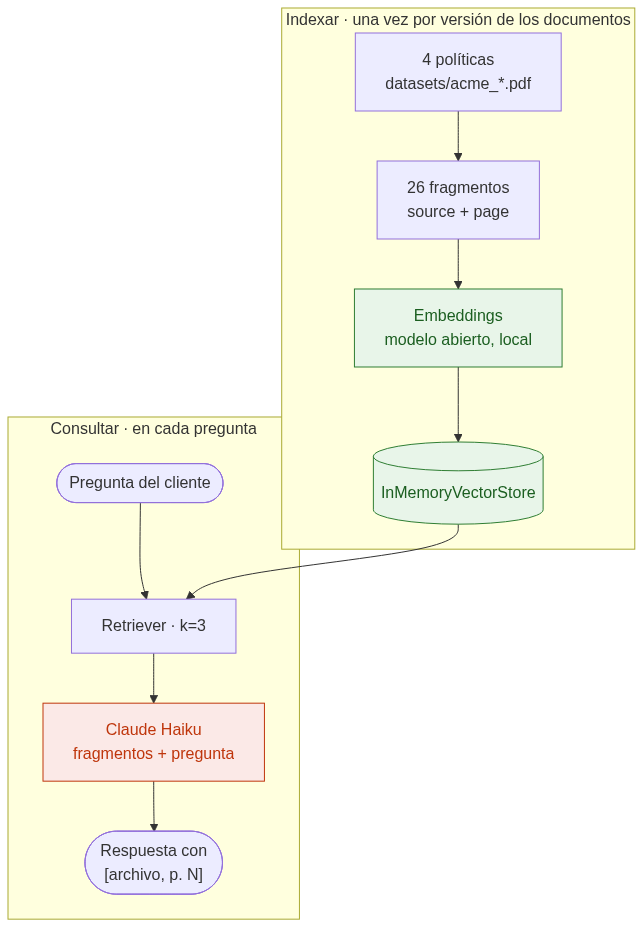

<details><summary>Código Mermaid</summary>

```mermaid
flowchart TB
    subgraph IDX["Indexar · una vez por versión de los documentos"]
        D["4 políticas<br/>datasets/acme_*.pdf"] --> F["26 fragmentos<br/>source + page"]
        F --> E["Embeddings<br/>modelo abierto, local"]
        E --> I[("InMemoryVectorStore")]
    end
    subgraph ASK["Consultar · en cada pregunta"]
        P(["Pregunta del cliente"]) --> R["Retriever · k=3"]
        R --> M["Claude Haiku<br/>fragmentos + pregunta"]
        M --> A(["Respuesta con<br/>[archivo, p. N]"])
    end
    I --> R

    classDef local fill:#e8f5e9,stroke:#2e7d32,color:#1b5e20
    classDef claude fill:#fbe9e7,stroke:#bf360c,color:#bf360c
    class E,I local
    class M claude
```

</details>

En verde lo que corre en tu equipo, sin costo por uso; en naranja, la única pieza que llama a una API de pago.

## Objetivos

Al terminar podrás:

1. Convertir un índice vectorial en un *retriever*.
2. Pasarle a Claude los fragmentos recuperados con su fuente y pedirle que cite archivo y página.
3. Juntar recuperación y respuesta en una cadena con `@chain`.
4. Ver qué hace el modelo cuando los fragmentos no contienen la respuesta.
5. Cambiar el retriever de la cadena sin tocar el resto.
6. Comprobar, sin modelo, que cada cita corresponde a un fragmento recuperado.

## Contenido

- [0. Preparación de los modelos](#0.-Preparación-de-los-modelos)
- [1. El índice de L6](#1.-El-índice-de-L6)
- [2. El retriever](#2.-El-retriever)
- [3. Responder con fuentes](#3.-Responder-con-fuentes)
- [4. Todo en una cadena, y una pregunta sin respuesta](#4.-Todo-en-una-cadena,-y-una-pregunta-sin-respuesta)
- [5. La misma cadena con otro retriever](#5.-La-misma-cadena-con-otro-retriever)
- [6. Comprobar las citas](#6.-Comprobar-las-citas)
- [Práctica breve](#Práctica-breve)
- [Referencias](#Referencias)

**Preparación:** igual que en L1 y L6. Ver [SETUP.md](../SETUP.md).

El recorrido realiza **3 llamadas a Claude Haiku**: una en la sección 3, una en la 4 y una en la 5. Los embeddings corren en el equipo, sin costo por uso.

## 0. Preparación de los modelos

Usamos **dos modelos**: Claude Haiku genera la respuesta, con la misma configuración de L1, y el modelo abierto de L6 convierte texto en vectores.

LangSmith es opcional: con `LANGSMITH_TRACING=true`, el recorrido genera **4 trazas** (el retriever de la sección 2 y las llamadas de las secciones 3, 4 y 5). Los embeddings no crean trazas propias.

In [1]:
import os

from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic
from langchain_community.embeddings import FastEmbedEmbeddings

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=500,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)
# Modelo abierto y multilingüe: corre en este equipo, sin API key ni costo por uso.
embeddings = FastEmbedEmbeddings(model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print("Trazas en LangSmith:", os.getenv("LANGSMITH_TRACING", "false"))

Trazas en LangSmith: false


## 1. El índice de L6

Sin modelo. Repetimos la carga, la fragmentación y el índice en memoria de L6: con 26 fragmentos se reconstruye en segundos. Si prefieres el índice guardado en L7, cámbialo por `FAISS.load_local("../data/faiss_acme", embeddings, allow_dangerous_deserialization=True)`: el resto del notebook no cambia.

In [2]:
from pathlib import Path

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pypdf import PdfReader

pages = []
for path in sorted(Path("../datasets").glob("acme_*.pdf")):
    for number, page in enumerate(PdfReader(path).pages, 1):
        pages.append(Document(page.extract_text(), metadata={"source": path.name, "page": number}))

splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=60)
chunks = splitter.split_documents(pages)
vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)

print(len(pages), "páginas →", len(chunks), "fragmentos indexados")

8 páginas → 26 fragmentos indexados


## 2. El retriever

`as_retriever` envuelve el índice con la misma interfaz de los modelos y las plantillas: `invoke`. Recibe una pregunta y devuelve una lista de `Document`. Con `k=3` trae los tres fragmentos más cercanos.

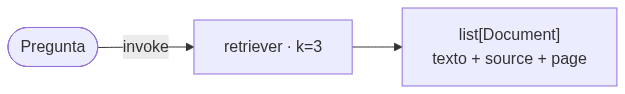

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q(["Pregunta"]) -->|invoke| R["retriever · k=3"]
    R --> D["list[Document]<br/>texto + source + page"]
```

</details>

La pregunta tiene **dos partes**: cuándo llega el dinero y si puede llegar a una cuenta de otro banco. Mira qué fragmentos trae el retriever para cada una.

In [3]:
retriever = vector_store.as_retriever(search_kwargs={"k": 3})

question = (
    "Firmé un Crédito Libre Inversión el viernes a las 5 de la tarde. "
    "¿Cuándo me desembolsan y puedo recibir el dinero en mi cuenta de otro banco?"
)
docs = retriever.invoke(question)
for doc in docs:
    print(doc.metadata["source"], "p.", doc.metadata["page"], "|", doc.page_content[:80].replace("\n", " "))

acme_disbursement_policy.pdf p. 1 | día. - Crédito Libre Inversión firmado después de las 3:00 p. m., en fin de sema
acme_disbursement_policy.pdf p. 2 | 5. Derecho de retracto El cliente puede retractarse del crédito dentro de los 5 
acme_collections_policy.pdf p. 1 | un aviso con 20 días calendario de anticipación. - Desde 91 días: la obligación 


El primer fragmento trae la regla del Crédito Libre Inversión firmado después de las 3:00 p. m. Los otros dos hablan de plazos (el retracto y los días de mora), pero no de la cuenta de destino. La regla «solo en la cuenta ACME del titular» está en otro fragmento de la misma página que quedó fuera de los tres más cercanos: **la recuperación cubrió solo la mitad de la pregunta**.

## 3. Responder con fuentes

Ahora sí llamamos a Claude. Le pasamos los fragmentos recuperados como **contexto**, cada uno precedido por su fuente con el formato `[archivo, p. N]`. El *system prompt* le pide responder solo con esos fragmentos, citar cada dato y decir cuándo no encuentra la respuesta.

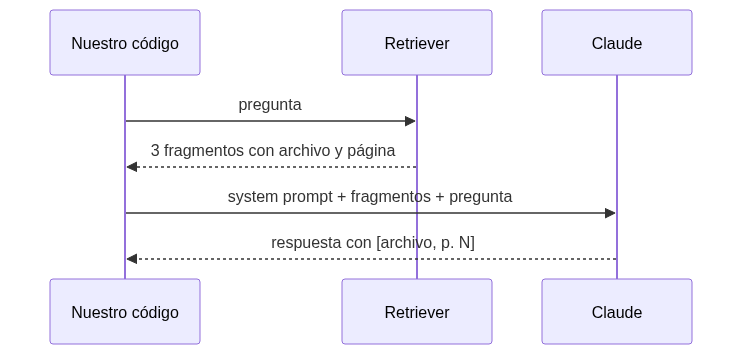

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant C as Nuestro código
    participant R as Retriever
    participant M as Claude
    C->>R: pregunta
    R-->>C: 3 fragmentos con archivo y página
    C->>M: system prompt + fragmentos + pregunta
    M-->>C: respuesta con [archivo, p. N]
```

</details>

In [4]:
from langchain_core.prompts import ChatPromptTemplate

SYSTEM_PROMPT = """\
Eres el asistente de soporte de ACME, una fintech.
Responde solo con la información de los fragmentos de documentos que recibes.
Después de cada dato, cita su fuente con el formato [archivo, p. N], tal como aparece en el fragmento.
Si los fragmentos no contienen la respuesta, o solo una parte, di qué no está en los documentos consultados y no lo inventes.
No prometas aprobaciones ni des asesoría financiera personalizada.
"""

prompt = ChatPromptTemplate.from_messages(
    [("system", SYSTEM_PROMPT), ("human", "Fragmentos:\n\n{context}\n\nPregunta: {question}")]
)

context = "\n\n".join(
    f"[{doc.metadata['source']}, p. {doc.metadata['page']}]\n{doc.page_content}" for doc in docs
)
print(context)

[acme_disbursement_policy.pdf, p. 1]
día.
- Crédito Libre Inversión firmado después de las 3:00 p. m., en fin de semana o en festivo: el
desembolso se hace el siguiente día hábil.
- El monto máximo desembolsado por cliente en un mismo día es 40.000.000 COP.
Política de desembolsos ACME - página 1

[acme_disbursement_policy.pdf, p. 2]
5. Derecho de retracto
El cliente puede retractarse del crédito dentro de los 5 días hábiles siguientes al desembolso. Para hacerlo
debe devolver el monto total desembolsado desde su cuenta ACME. En ese caso no paga intereses ni
seguro por los días transcurridos.
Pasado ese plazo, el crédito solo puede terminarse mediante un pago anticipado total, según la guía de
costos y pagos.

[acme_collections_policy.pdf, p. 1]
un aviso con 20 días calendario de anticipación.
- Desde 91 días: la obligación pasa a cobro prejurídico y se bloquea la solicitud de nuevos créditos.
Política de cobranza y reestructuración ACME - página 1


In [5]:
messages = prompt.format_messages(context=context, question=question)
answer = model.invoke(messages)
print(answer.text)

Con la información de los documentos consultados, puedo responder parcialmente:

**Sobre el desembolso:** Un Crédito Libre Inversión firmado después de las 3:00 p. m., en fin de semana o en festivo, se desembolsa el siguiente día hábil [acme_disbursement_policy.pdf, p. 1]. Como firmó un viernes a las 5:00 p. m., el desembolso se haría el siguiente día hábil (en principio, el lunes, salvo que sea festivo). También existe un límite de 40.000.000 COP desembolsados por cliente en un mismo día [acme_disbursement_policy.pdf, p. 1].

**Sobre recibir el dinero en otro banco:** Los fragmentos consultados no indican si el desembolso puede hacerse a una cuenta de otra entidad. Lo único que mencionan es el derecho de retracto, que requiere devolver el monto desde su cuenta ACME [acme_disbursement_policy.pdf, p. 2]. No tengo información suficiente para confirmar si puede recibir el dinero en una cuenta de otro banco. Le recomiendo consultar con el equipo de soporte de ACME por los canales oficiales

Revisa la respuesta: ¿el dato del siguiente día hábil viene con su cita? ¿Qué dice sobre la cuenta de otro banco? Como ese fragmento no llegó al contexto, lo correcto es decir que no está en los documentos consultados, no inventar un «sí» o un «no». Fíjate también si el modelo deduce algo que el fragmento no dice, como el día de la semana: una deducción razonable sigue sin tener cita. En la práctica 1 subirás `k` para buscar el fragmento que falta.

## 4. Todo en una cadena, y una pregunta sin respuesta

Los tres pasos de la sección 3 (recuperar, armar el contexto y llamar al modelo) se repiten con cada pregunta. Los juntamos en una función con `@chain`, como en L1: se usa con `invoke` como cualquier *runnable* y en LangSmith aparece como **una sola traza** con el retriever y el modelo adentro.

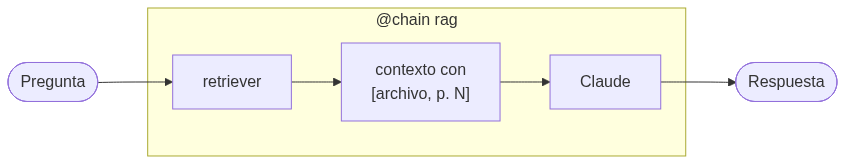

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    subgraph RAG ["@chain rag"]
        R["retriever"] --> C["contexto con<br/>[archivo, p. N]"] --> M["Claude"]
    end
    Q(["Pregunta"]) --> R
    M --> A(["Respuesta"])
```

</details>

Probamos una pregunta que los documentos **no** responden: ACME solo ofrece créditos de consumo, y las políticas no hablan de tarjetas de crédito. El retriever siempre devuelve tres fragmentos, aunque ninguno sirva. Lo que evita que Claude invente es la regla del *system prompt*.

In [6]:
from langchain_core.runnables import chain


def format_context(docs):
    return "\n\n".join(
        f"[{doc.metadata['source']}, p. {doc.metadata['page']}]\n{doc.page_content}" for doc in docs
    )


@chain
def rag(question: str):
    docs = retriever.invoke(question)
    return model.invoke(prompt.format_messages(context=format_context(docs), question=question))

In [7]:
card_answer = rag.invoke("¿Qué beneficios tiene la tarjeta de crédito de ACME?")
print(card_answer.text)

Según los fragmentos consultados, no encuentro información sobre beneficios de una tarjeta de crédito de ACME. Los documentos disponibles tratan sobre la política de crédito de consumo (Crédito Express y Crédito Libre Inversión) y la guía de costos y pagos de créditos, pero no mencionan tarjetas de crédito.

Si necesitas esa información, te recomiendo consultar el catálogo de productos actualizado de ACME o contactar directamente a su equipo de atención al cliente.


Los fragmentos recuperados hablan de créditos de consumo, no de tarjetas. ¿La respuesta explica que el dato no está o inventa beneficios? ¿Ofrece información que no se le pidió?

## 5. La misma cadena con otro retriever

La cadena solo necesita un objeto con `invoke` que devuelva documentos. Cambiamos el retriever por uno de Chroma con el **filtro por documento** de L7: una pregunta sobre mora se busca solo en la política de cobranza. Esta vez la colección vive en memoria (sin `persist_directory`), para no depender de haber ejecutado L7.

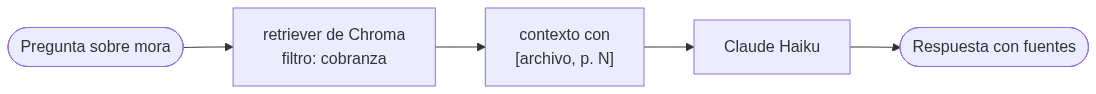

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q(["Pregunta sobre mora"]) --> R["retriever de Chroma<br/>filtro: cobranza"]
    R --> C["contexto con<br/>[archivo, p. N]"]
    C --> M["Claude Haiku"]
    M --> A(["Respuesta con fuentes"])
```

</details>

In [8]:
from langchain_chroma import Chroma

chroma_store = Chroma.from_documents(
    chunks, embeddings, collection_name="acme_policies_l4", collection_metadata={"hnsw:space": "cosine"}
)
collections_retriever = chroma_store.as_retriever(
    search_kwargs={"k": 3, "filter": {"source": "acme_collections_policy.pdf"}}
)


@chain
def collections_rag(question: str):
    docs = collections_retriever.invoke(question)
    return model.invoke(prompt.format_messages(context=format_context(docs), question=question))


arrears_answer = collections_rag.invoke(
    "Tengo 45 días de mora en mi crédito. ¿Puedo reestructurarlo y cuánto puedo ampliar el plazo?"
)
print(arrears_answer.text)

Según los documentos consultados, sí es posible solicitar una reestructuración, pero no tengo información suficiente para confirmar que tu caso califique ni para indicarte la ampliación exacta de tu plazo.

Lo que sí dice la política:
- Un cliente con hasta 90 días de mora puede solicitar una reestructuración desde la app [acme_collections_policy.pdf, p. 2]. Con 45 días de mora, estarías dentro de ese rango.
- La reestructuración puede ampliar el plazo restante hasta en 24 meses, sin superar el plazo máximo del producto [acme_collections_policy.pdf, p. 2].
- Cada crédito admite una sola reestructuración por año [acme_collections_policy.pdf, p. 2].
- Una reestructuración aprobada no borra el historial de mora ya reportado [acme_collections_policy.pdf, p. 2].

Lo que no puedo confirmar con los fragmentos disponibles:
- Si tu crédito en particular cumple las condiciones para la reestructuración, ni si será aprobada. No puedo prometer una aprobación.
- Cuánto podría ampliarse tu plazo espe

Con el filtro, los tres fragmentos son de la política de cobranza. ¿La respuesta cita la página 2 para el límite de 90 días y la ampliación de hasta 24 meses? ¿Promete que la reestructuración será aprobada, o aclara que eso depende de la evaluación?

## 6. Comprobar las citas

Una respuesta convincente no basta. Esta sección no llama a ningún modelo: extrae las citas `[archivo, p. N]` de la respuesta de la sección 3 y comprueba que **cada una corresponde a un fragmento que de verdad recuperamos**. Una cita a una página que no estaba en el contexto sería inventada.

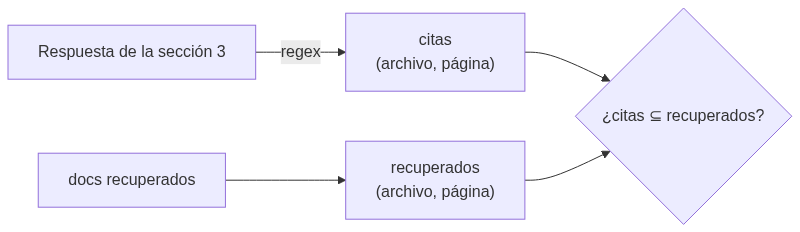

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    A["Respuesta de la sección 3"] -->|regex| C["citas<br/>(archivo, página)"]
    D["docs recuperados"] --> R["recuperados<br/>(archivo, página)"]
    C --> T{"¿citas ⊆ recuperados?"}
    R --> T
```

</details>

In [9]:
import re

cited = set(re.findall(r"\[([\w.-]+\.pdf), p\. (\d+)\]", answer.text))
retrieved = {(doc.metadata["source"], str(doc.metadata["page"])) for doc in docs}

print("Citas en la respuesta:", cited)
print("Fragmentos recuperados:", retrieved)
print("¿Todas las citas vienen del contexto?", bool(cited) and cited <= retrieved)

Citas en la respuesta: {('acme_disbursement_policy.pdf', '1'), ('acme_disbursement_policy.pdf', '2')}
Fragmentos recuperados: {('acme_disbursement_policy.pdf', '1'), ('acme_disbursement_policy.pdf', '2'), ('acme_collections_policy.pdf', '1')}
¿Todas las citas vienen del contexto? True


Esta comprobación detecta citas inventadas o respuestas sin citas, pero no prueba que cada dato diga lo mismo que su fuente. En la semana de evaluación mediremos el sustento en fuentes con un conjunto de preguntas y un juez.

## Práctica breve

1. Repite la pregunta de la sección 2 con `k=5`. ¿Aparece el fragmento de la cuenta de destino? ¿Cambia la respuesta de Claude?
2. Pregunta con `rag.invoke`: *«¿Puedo pagar mi cuota en efectivo?»* y comprueba las citas con la sección 6.
3. Quita del *system prompt* la regla «Si los fragmentos no contienen la respuesta…» y repite la pregunta de la tarjeta de crédito. ¿Qué cambia?
4. Cambia el filtro de la sección 5 por `{"source": "acme_fees_guide.pdf"}` y repite la pregunta de la mora. ¿Qué responde Claude cuando los fragmentos no sirven?

En la semana 5 la cadena recordará la conversación ([L9](L09-ConversationalRAG.ipynb) y [L10](L10-Memory.ipynb)) y mediremos la recuperación con las 22 preguntas de `datasets/acme_questions.csv`.

## Referencias

**Learning LangChain**, Mayo Oshin y Nuno Campos, O'Reilly, capítulo 3: [`a-basic-rag.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch3/py/a-basic-rag.py), retriever, prompt con contexto y `@chain`. El libro usa PGVector y GPT; aquí, un índice en memoria, Claude Haiku y citas de archivo y página.

**AI Engineering**, Chip Huyen, capítulo 6: RAG y agentes.

- [RAG en LangChain](https://docs.langchain.com/oss/python/langchain/rag)
- [Retrievers](https://docs.langchain.com/oss/python/integrations/retrievers)